In [1]:
import pandas as pd

In [2]:
# 1. Load your model-ready dataset
df = pd.read_csv("model_ready_dataset.csv")
df["date"] = pd.to_datetime(df["date"])

In [3]:
# 2. Define features (X) and target (y)
target = "avg_kwh_per_household"
features = [
    "total_households",
    "avg_temperature_c",
    "avg_humidity_pct",
    "avg_rainfall_mm_per_day",
    "avg_wind_speed_ms",
    "year",
    "month",
    "quarter",
    "kwh_lag_1",
    "kwh_lag_2",
    "temp_lag_1",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_lag_1",
]

# 3. Chronological Split (Train: 2018–2024, Test: 2025–2026)
train_df = df[df["date"].dt.year < 2025]
test_df = df[df["date"].dt.year >= 2025]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print(f"Training Set Shape: {X_train.shape} (Years: 2018–2024)")
print(f"Testing Set Shape: {X_test.shape} (Years: 2025–2026)")

Training Set Shape: (82, 14) (Years: 2018–2024)
Testing Set Shape: (18, 14) (Years: 2025–2026)


In [4]:
df = df.sort_values("date").reset_index(drop=True)

print(df.shape)   # patut (100, 19)

(100, 19)


In [9]:
# 2. Config
TARGET = "avg_kwh_per_household"
TEST_MONTHS = 18

DROP_COLS = [
    "date",
    TARGET,
    "domestic_consumption_m_kwh",
    "total_consumption_kwh",
    "temp_fahrenheit",
    "total_households",
]

# 3. Time-based split (last 18 months = test)
train = df.iloc[:-TEST_MONTHS]
test = df.iloc[-TEST_MONTHS:]

# 4. Build X and y
X_train = train.drop(columns=DROP_COLS)
y_train = train[TARGET]
X_test = test.drop(columns=DROP_COLS)
y_test = test[TARGET]

# 5. Verify
print(f"Train: {train['date'].min():%Y-%m} to {train['date'].max():%Y-%m} ({len(train)} rows)")
print(f"Test : {test['date'].min():%Y-%m} to {test['date'].max():%Y-%m} ({len(test)} rows)")
print(X_train.shape, X_test.shape)
print(X_train.columns.tolist())

Train: 2018-03 to 2024-12 (82 rows)
Test : 2025-01 to 2026-06 (18 rows)
(82, 13) (18, 13)
['year', 'month', 'quarter', 'avg_temperature_c', 'avg_humidity_pct', 'avg_rainfall_mm_per_day', 'avg_wind_speed_ms', 'kwh_lag_1', 'kwh_lag_2', 'temp_lag_1', 'humidity_lag_1', 'rainfall_lag_1', 'wind_lag_1']


In [10]:
import numpy as np

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline 1: same month last year (seasonal naive)
df["pred_seasonal_naive"] = df[TARGET].shift(12)

# Baseline 2: same as last month (naive)
df["pred_naive"] = df[TARGET].shift(1)

# Re-slice the test set so it includes the new columns
test = df.iloc[-TEST_MONTHS:]

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name:24s} MAE={mae:7.3f}  RMSE={rmse:7.3f}  MAPE={mape:5.2f}%")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "MAPE": mape}

results = []
results.append(evaluate(test[TARGET], test["pred_seasonal_naive"], "Seasonal naive (t-12)"))
results.append(evaluate(test[TARGET], test["pred_naive"], "Naive (t-1)"))

Seasonal naive (t-12)    MAE= 17.602  RMSE= 19.858  MAPE= 4.69%
Naive (t-1)              MAE= 15.126  RMSE= 18.527  MAPE= 3.95%


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

LAG_KWH = ["kwh_lag_1", "kwh_lag_2"]

feature_sets = {
    "A (with kWh lags)": list(X_train.columns),
    "B (no kWh lags)": [c for c in X_train.columns if c not in LAG_KWH],
}

for set_name, cols in feature_sets.items():
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    results.append(evaluate(y_test, pred, f"Ridge | {set_name}"))

Ridge | A (with kWh lags) MAE= 11.997  RMSE= 16.357  MAPE= 3.12%
Ridge | B (no kWh lags)  MAE= 15.667  RMSE= 19.850  MAPE= 4.09%


In [13]:
from sklearn.ensemble import RandomForestRegressor

for set_name, cols in feature_sets.items():
    model = RandomForestRegressor(n_estimators=300, random_state=42)
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    results.append(evaluate(y_test, pred, f"Random Forest | {set_name}"))

Random Forest | A (with kWh lags) MAE= 14.989  RMSE= 18.863  MAPE= 3.88%
Random Forest | B (no kWh lags) MAE= 22.516  RMSE= 26.062  MAPE= 5.88%


In [14]:
rf = RandomForestRegressor(n_estimators=300, random_state=42)
colsB = feature_sets["B (no kWh lags)"]
rf.fit(X_train[colsB], y_train)
pred = rf.predict(X_test[colsB])

print("Train mean:", y_train.mean().round(1))
print("Test mean :", y_test.mean().round(1))
print("Mean error (pred - actual):", (pred - y_test).mean().round(1))

Train mean: 339.3
Test mean : 375.2
Mean error (pred - actual): -22.2


In [16]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 4.7 MB/s eta 0:00:11
   - -------------------------------------- 2.1/48.9 MB 5.6 MB/s eta 0:00:09
   -- ------------------------------------- 3.7/48.9 MB 6.2 MB/s eta 0:00:08
   --- ------------------------------------ 4.5/48.9 MB 6.3 MB/s eta 0:00:08
   ---- ----------------------------------- 6.0/48.9 MB 6.0 MB/s eta 0:00:08
   ------ --------------------------------- 7.6/48.9 MB 6.3 MB/s eta 0:00:07
   ------- -------------------------------- 8.9/48.9 MB 6.3 MB/s eta 0:00:07
   -------- ------------------------------- 10.0/48.9 MB 6.2 MB/s eta 0:00:07
   --------- ------------------------------ 11.5/48.9 MB 6.3 MB/s eta 0:00:06
   ---------- ----------------------------- 12.8/48.9 MB 6.3 MB/s eta 0:00:06
   ----------- ---------------------------- 14.2/48.9 MB 6.2 MB/s eta 0:00:06
   ------------ --------------------------- 15.5/48.9 MB 6.3 MB/s eta 0:00:06
 

In [17]:
from xgboost import XGBRegressor   # pip install xgboost if needed

for set_name, cols in feature_sets.items():
    model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    results.append(evaluate(y_test, pred, f"XGBoost | {set_name}"))


XGBoost | A (with kWh lags) MAE= 16.077  RMSE= 19.584  MAPE= 4.16%
XGBoost | B (no kWh lags) MAE= 18.479  RMSE= 22.699  MAPE= 4.78%


In [18]:
# Same-month-last-year value (known at forecast time, so no leakage)
df["yoy_base"] = df[TARGET].shift(12)
df["target_diff"] = df[TARGET] - df["yoy_base"]

# Rebuild train/test. Train loses its first 12 rows (no year-ago value yet)
train2 = df.iloc[:-TEST_MONTHS].dropna(subset=["yoy_base"])
test2 = df.iloc[-TEST_MONTHS:]
print("Train rows:", len(train2), "| Test rows:", len(test2))

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models2 = {
    "Random Forest (diff)": RandomForestRegressor(n_estimators=300, random_state=42),
    "XGBoost (diff)": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
}

for set_name, cols in feature_sets.items():
    for model_name, model in models2.items():
        model.fit(train2[cols], train2["target_diff"])
        pred = model.predict(test2[cols]) + test2["yoy_base"]   # add last year's value back
        results.append(evaluate(test2[TARGET], pred, f"{model_name} | {set_name}"))

Train rows: 70 | Test rows: 18
Random Forest (diff) | A (with kWh lags) MAE= 13.379  RMSE= 17.270  MAPE= 3.65%
XGBoost (diff) | A (with kWh lags) MAE= 11.464  RMSE= 15.303  MAPE= 3.05%
Random Forest (diff) | B (no kWh lags) MAE= 14.985  RMSE= 20.504  MAPE= 4.09%
XGBoost (diff) | B (no kWh lags) MAE= 18.260  RMSE= 23.751  MAPE= 4.92%


In [19]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=3)
colsA = feature_sets["A (with kWh lags)"]

xgb_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.05, 0.1],
}

gs_xgb = GridSearchCV(
    XGBRegressor(random_state=42),
    xgb_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
)
gs_xgb.fit(train2[colsA], train2["target_diff"])

print("Best params:", gs_xgb.best_params_)
print("CV MAE:", round(-gs_xgb.best_score_, 3))

pred = gs_xgb.predict(test2[colsA]) + test2["yoy_base"]
results.append(evaluate(test2[TARGET], pred, "XGBoost (diff, tuned) | A"))

Best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
CV MAE: 18.569
XGBoost (diff, tuned) | A MAE= 15.784  RMSE= 18.676  MAPE= 4.20%


In [20]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

colsB = feature_sets["B (no kWh lags)"]
tscv = TimeSeriesSplit(n_splits=3)

pipe = make_pipeline(StandardScaler(), Ridge())
grid = {"ridge__alpha": [0.1, 1, 10, 30, 100]}

gs_ridge = GridSearchCV(pipe, grid, cv=tscv, scoring="neg_mean_absolute_error")
gs_ridge.fit(X_train[colsB], y_train)   # raw target, 82 rows

print("Best alpha:", gs_ridge.best_params_)
print("CV MAE:", round(-gs_ridge.best_score_, 3))

pred = gs_ridge.predict(X_test[colsB])
results.append(evaluate(y_test, pred, "Ridge (tuned) | B"))

Best alpha: {'ridge__alpha': 30}
CV MAE: 16.115
Ridge (tuned) | B        MAE= 16.231  RMSE= 19.901  MAPE= 4.20%


In [21]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

colsB = feature_sets["B (no kWh lags)"]
tscv = TimeSeriesSplit(n_splits=3)

pipe = make_pipeline(StandardScaler(), Ridge())
grid = {"ridge__alpha": [0.1, 1, 10, 30, 100]}

gs_ridge = GridSearchCV(pipe, grid, cv=tscv, scoring="neg_mean_absolute_error")
gs_ridge.fit(X_train[colsB], y_train)   # raw target, 82 rows

print("Best alpha:", gs_ridge.best_params_)
print("CV MAE:", round(-gs_ridge.best_score_, 3))

pred = gs_ridge.predict(X_test[colsB])
results.append(evaluate(y_test, pred, "Ridge (tuned) | B"))

Best alpha: {'ridge__alpha': 30}
CV MAE: 16.115
Ridge (tuned) | B        MAE= 16.231  RMSE= 19.901  MAPE= 4.20%


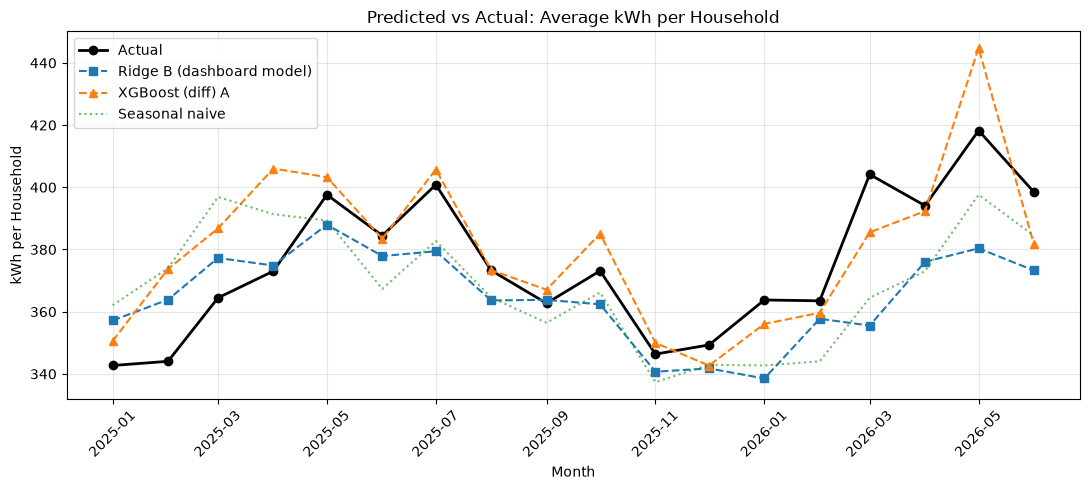

Ridge B mean error : -10.11
XGB A mean error   : 5.2


In [23]:
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

colsA = feature_sets["A (with kWh lags)"]
colsB = feature_sets["B (no kWh lags)"]

# Final models (default parameters)
ridge_B = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train[colsB], y_train)
xgb_A = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
xgb_A.fit(train2[colsA], train2["target_diff"])

pred_ridge_B = ridge_B.predict(X_test[colsB])
pred_xgb_A = xgb_A.predict(test2[colsA]) + test2["yoy_base"].values

plt.figure(figsize=(11, 5))
plt.plot(test["date"], y_test, "k-o", label="Actual", linewidth=2)
plt.plot(test["date"], pred_ridge_B, "--s", label="Ridge B (dashboard model)")
plt.plot(test["date"], pred_xgb_A, "--^", label="XGBoost (diff) A")
plt.plot(test["date"], test["pred_seasonal_naive"], ":", label="Seasonal naive", alpha=0.7)
plt.title("Predicted vs Actual: Average kWh per Household")
plt.xlabel("Month")
plt.ylabel("kWh per Household")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("pred_vs_actual.png", dpi=200)
plt.show()

# Bias check
print("Ridge B mean error :", round((pred_ridge_B - y_test).mean(), 2))
print("XGB A mean error   :", round((pred_xgb_A - y_test.values).mean(), 2))

In [24]:
from sklearn.inspection import permutation_importance

colsB = feature_sets["B (no kWh lags)"]

# 1. Standardised coefficients (features are on the same scale, so sizes are comparable)
coefs = pd.Series(ridge_B.named_steps["ridge"].coef_, index=colsB).sort_values(key=abs, ascending=False)
print("Standardised coefficients:")
print(coefs.round(2))

# 2. Permutation importance on the test set (how much MAE worsens if a feature is shuffled)
perm = permutation_importance(
    ridge_B, X_test[colsB], y_test,
    scoring="neg_mean_absolute_error", n_repeats=30, random_state=42
)
perm_s = pd.Series(perm.importances_mean, index=colsB).sort_values(ascending=False)
print("\nPermutation importance (increase in MAE):")
print(perm_s.round(2))

Standardised coefficients:
year                       14.79
avg_temperature_c          10.66
avg_humidity_pct            8.42
avg_rainfall_mm_per_day    -6.94
month                      -4.01
humidity_lag_1             -2.84
quarter                    -1.87
avg_wind_speed_ms          -1.39
wind_lag_1                 -1.32
temp_lag_1                  0.43
rainfall_lag_1              0.43
dtype: float64

Permutation importance (increase in MAE):
avg_temperature_c          7.15
year                       1.54
humidity_lag_1             1.52
avg_rainfall_mm_per_day    0.67
wind_lag_1                 0.36
avg_wind_speed_ms          0.30
rainfall_lag_1             0.17
temp_lag_1                 0.14
avg_humidity_pct          -0.29
month                     -0.55
quarter                   -0.56
dtype: float64


In [25]:
colsC = ["year", "month", "avg_temperature_c", "avg_humidity_pct",
         "avg_rainfall_mm_per_day", "avg_wind_speed_ms"]

ridge_C = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train[colsC], y_train)
pred_C = ridge_C.predict(X_test[colsC])
results.append(evaluate(y_test, pred_C, "Ridge | C (current weather only)"))
print("Mean error:", round((pred_C - y_test).mean(), 2))

# Effect per real unit (useful for dashboard insights)
scaler = ridge_C.named_steps["standardscaler"]
ridge = ridge_C.named_steps["ridge"]
print((pd.Series(ridge.coef_ / scaler.scale_, index=colsC)).round(2))

Ridge | C (current weather only) MAE= 17.175  RMSE= 21.198  MAPE= 4.48%
Mean error: -11.97
year                        6.89
month                      -1.51
avg_temperature_c          19.86
avg_humidity_pct            4.56
avg_rainfall_mm_per_day    -1.89
avg_wind_speed_ms          -8.13
dtype: float64


In [26]:
import numpy as np

def add_cyclical(X):
    X = X.copy()
    X["month_sin"] = np.sin(2 * np.pi * X["month"] / 12)
    X["month_cos"] = np.cos(2 * np.pi * X["month"] / 12)
    return X

colsC2 = ["year", "month_sin", "month_cos", "avg_temperature_c",
          "avg_humidity_pct", "avg_rainfall_mm_per_day", "avg_wind_speed_ms"]

Xtr_c = add_cyclical(X_train)
Xte_c = add_cyclical(X_test)

ridge_C2 = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr_c[colsC2], y_train)
pred_C2 = ridge_C2.predict(Xte_c[colsC2])
results.append(evaluate(y_test, pred_C2, "Ridge | C2 (cyclical month)"))
print("Mean error:", round((pred_C2 - y_test).mean(), 2))

# Real-world range of temperature, to put the +19.9 per °C in context
print("Temp std:", round(df["avg_temperature_c"].std(), 2),
      "| min:", round(df["avg_temperature_c"].min(), 2),
      "| max:", round(df["avg_temperature_c"].max(), 2))

Ridge | C2 (cyclical month) MAE= 14.710  RMSE= 18.615  MAPE= 3.83%
Mean error: -9.25
Temp std: 0.65 | min: 25.34 | max: 28.51


In [27]:
import joblib
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

FEATURES = ["year", "month_sin", "month_cos", "avg_temperature_c",
            "avg_humidity_pct", "avg_rainfall_mm_per_day", "avg_wind_speed_ms"]

full = df.copy()
full["month_sin"] = np.sin(2 * np.pi * full["month"] / 12)
full["month_cos"] = np.cos(2 * np.pi * full["month"] / 12)

final_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
final_model.fit(full[FEATURES], full[TARGET])

# Save model + everything the dashboard needs
joblib.dump({
    "model": final_model,
    "features": FEATURES,
    "ranges": {
        "avg_temperature_c": (full["avg_temperature_c"].min(), full["avg_temperature_c"].max()),
        "avg_humidity_pct": (full["avg_humidity_pct"].min(), full["avg_humidity_pct"].max()),
        "avg_rainfall_mm_per_day": (full["avg_rainfall_mm_per_day"].min(), full["avg_rainfall_mm_per_day"].max()),
        "avg_wind_speed_ms": (full["avg_wind_speed_ms"].min(), full["avg_wind_speed_ms"].max()),
    },
}, "final_model.pkl")

# Per-unit effects for the insights page
sc = final_model.named_steps["standardscaler"]
rg = final_model.named_steps["ridge"]
print(pd.Series(rg.coef_ / sc.scale_, index=FEATURES).round(2))
print("Training ranges:", {k: tuple(round(x, 2) for x in v) for k, v in
      {"temp": (full["avg_temperature_c"].min(), full["avg_temperature_c"].max())}.items()})

year                        7.90
month_sin                   4.17
month_cos                 -11.42
avg_temperature_c          14.88
avg_humidity_pct            0.54
avg_rainfall_mm_per_day    -0.07
avg_wind_speed_ms          13.80
dtype: float64
Training ranges: {'temp': (np.float64(25.34), np.float64(28.51))}


In [ ]:
saved = joblib.load("final_model.pkl")
row = full.iloc[[-1]]
print("Predicted:", saved["model"].predict(row[saved["features"]])[0].round(1))
print("Actual   :", row[TARGET].values[0].round(1))

Predicted: 395.6
Actual   : 398.5


: 